# Modeling: Predicting total_UPDRS

In [1]:
# headers
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn.metrics as metrics
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.model_selection import cross_val_score, cross_validate, GridSearchCV
from sklearn.linear_model import LinearRegression

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/__init__.py:82: UserWarning: A NumPy version >=1.23.5 and <2.5.0 is required for this version of SciPy (detected version 2.5.4)
  import scipy.linalg  # noqa


## Train/Test Split

### Load the Data

No missing values, so no cleaning is needed here.

In [2]:
df = pd.read_csv("data/parkinsons_updrs.csv")
print(df.shape)
print(df.head())

(5875, 22)
   subject#  age  sex  test_time  motor_UPDRS  total_UPDRS  Jitter(%)  \
0         1   72    0     5.6431       28.199       34.398    0.00662   
1         1   72    0    12.6660       28.447       34.894    0.00300   
2         1   72    0    19.6810       28.695       35.389    0.00481   
3         1   72    0    25.6470       28.905       35.810    0.00528   
4         1   72    0    33.6420       29.187       36.375    0.00335   

   Jitter(Abs)  Jitter:RAP  Jitter:PPQ5  ...  Shimmer(dB)  Shimmer:APQ3  \
0     0.000034     0.00401      0.00317  ...        0.230       0.01438   
1     0.000017     0.00132      0.00150  ...        0.179       0.00994   
2     0.000025     0.00205      0.00208  ...        0.181       0.00734   
3     0.000027     0.00191      0.00264  ...        0.327       0.01106   
4     0.000020     0.00093      0.00130  ...        0.176       0.00679   

   Shimmer:APQ5  Shimmer:APQ11  Shimmer:DDA       NHR     HNR     RPDE  \
0       0.01309        0.

### Features and Target

The target is `total_UPDRS`. We drop both UPDRS columns and `subject#` from the features. `subject#` is kept separately in `groups` so we can split by patient.

In [3]:
y = df["total_UPDRS"]
X = df.drop(columns=["subject#", "motor_UPDRS", "total_UPDRS"])
groups = df["subject#"]
print(X.shape)
print(list(X.columns))

(5875, 19)
['age', 'sex', 'test_time', 'Jitter(%)', 'Jitter(Abs)', 'Jitter:RAP', 'Jitter:PPQ5', 'Jitter:DDP', 'Shimmer', 'Shimmer(dB)', 'Shimmer:APQ3', 'Shimmer:APQ5', 'Shimmer:APQ11', 'Shimmer:DDA', 'NHR', 'HNR', 'RPDE', 'DFA', 'PPE']


### Log Transform

The jitter, shimmer, and NHR columns are very right-skewed. We replace them with their log. This is done one row at a time with nothing learned from the data, so it is safe to do before the split.

In [4]:
skewed = [col for col in X.columns if col.startswith("Jitter") or col.startswith("Shimmer") or col == "NHR"]
print("Skew before:")
print(X[skewed].skew())

X[skewed] = np.log(X[skewed])
print("\nSkew after:")
print(X[skewed].skew())

Skew before:
Jitter(%)        6.451846
Jitter(Abs)      3.283075
Jitter:RAP       6.945438
Jitter:PPQ5      7.586205
Jitter:DDP       6.945376
Shimmer          3.312793
Shimmer(dB)      3.099221
Shimmer:APQ3     3.097223
Shimmer:APQ5     3.698061
Shimmer:APQ11    3.406958
Shimmer:DDA      3.097224
NHR              6.549123
dtype: float64

Skew after:
Jitter(%)        0.867603
Jitter(Abs)      0.111631
Jitter:RAP       0.802593
Jitter:PPQ5      1.071370
Jitter:DDP       0.802443
Shimmer          0.449032
Shimmer(dB)      0.424309
Shimmer:APQ3     0.262060
Shimmer:APQ5     0.397637
Shimmer:APQ11    0.310238
Shimmer:DDA      0.262043
NHR              0.363842
dtype: float64


### Split by Patient

`GroupShuffleSplit` puts 80% of the patients in training and 20% in test, so no patient is in both sets. The test set is not used again until the final evaluation.

In [5]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train = groups.iloc[train_idx]

print(f"Number of training records is {len(X_train)}")
print(f"Number of test records is {len(X_test)}")
print(f"Number of training patients is {groups_train.nunique()}")
print(f"Number of test patients is {groups.iloc[test_idx].nunique()}")
# check that no patient is in both sets
print(f"Patients in both sets: {set(groups_train) & set(groups.iloc[test_idx])}")

Number of training records is 4640
Number of test records is 1235
Number of training patients is 33
Number of test patients is 9
Patients in both sets: set()


### First Model Check

Plain linear regression on all features, scored on the training data, just to check that everything runs.

In [6]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

y_predicted = linear_model.predict(X_train)
print(f"The MAE is {metrics.mean_absolute_error(y_train, y_predicted)}")
print(f"The RMSE is {metrics.root_mean_squared_error(y_train, y_predicted)}")
print(f"The R^2 is {metrics.r2_score(y_train, y_predicted)}")

The MAE is 7.99721252036005
The RMSE is 9.68733145537251
The R^2 is 0.22742607317258023


## Cross Validation Setup

Every model uses the same 5 folds from `GroupKFold` on the training set, with `groups=groups_train` so a patient's recordings are never split between a training fold and a validation fold. `GroupKFold` has no randomness, so it gives the same folds every time it is used.

In [7]:
gkf = GroupKFold(n_splits=5)

# show which patients are in each validation fold
for i, (fold_train, fold_val) in enumerate(gkf.split(X_train, y_train, groups_train)):
    print(f"Fold {i}: {len(fold_val)} validation records, patients {sorted(groups_train.iloc[fold_val].unique().tolist())}")

Fold 0: 869 validation records, patients [1, 2, 15, 19, 29, 33]
Fold 1: 967 validation records, patients [16, 18, 23, 32, 38, 41, 42]
Fold 2: 971 validation records, patients [8, 10, 11, 12, 21, 35, 37]
Fold 3: 868 validation records, patients [3, 6, 7, 25, 28, 36]
Fold 4: 965 validation records, patients [4, 13, 17, 22, 24, 34, 39]


## Forward Feature Selection

We compare five feature groups: features picked by a linear model, features picked by a nonlinear model, features kept by Lasso, voice features + sex + age, and all features (voice + sex + age + test_time).

Both selections use the same loop. Start with no features. At each step, try adding each remaining feature, score it with a scaler + model pipeline on the shared folds, and keep the feature with the lowest CV MAE. A feature is only added if it lowers CV MAE by at least 0.5% compared to the current set. Otherwise we stop.

### Linear Selection

Selection with `LinearRegression`.

In [8]:
selected = []
remaining = list(X_train.columns)
current_mae = None
steps = []

while len(remaining) > 0:
    # try adding each remaining feature and keep the best one
    best_feature = None
    best_mae = None
    for feature in remaining:
        pipe = Pipeline([("scaler", StandardScaler()), ("linreg", LinearRegression())])
        scores = cross_val_score(pipe, X_train[selected + [feature]], y_train, cv=gkf,
                                 groups=groups_train, scoring="neg_mean_absolute_error")
        mae = -scores.mean()
        if best_mae is None or mae < best_mae:
            best_mae = mae
            best_feature = feature

    # first feature is always added; after that it needs at least 0.5% improvement
    if current_mae is None:
        improvement = None
    else:
        improvement = (current_mae - best_mae) / current_mae * 100
        if improvement < 0.5:
            print(f"Stopping: best next feature was {best_feature} with only {improvement:.2f}% improvement")
            break

    selected.append(best_feature)
    remaining.remove(best_feature)
    current_mae = best_mae
    steps.append({"step": len(selected), "feature added": best_feature,
                  "CV MAE": best_mae, "% improvement": improvement})

print(pd.DataFrame(steps))
linear_features = selected
print(f"Linear selected features: {linear_features}")

Stopping: best next feature was Jitter:DDP with only -0.02% improvement
   step feature added    CV MAE  % improvement
0     1           age  8.468314            NaN
1     2    Jitter:RAP  8.320059       1.750696
Linear selected features: ['age', 'Jitter:RAP']


### Nonlinear Selection

Same loop, but with `KNeighborsRegressor(n_neighbors=50)` as the model.

In [9]:
from sklearn.neighbors import KNeighborsRegressor

selected = []
remaining = list(X_train.columns)
current_mae = None
steps = []

while len(remaining) > 0:
    # try adding each remaining feature and keep the best one
    best_feature = None
    best_mae = None
    for feature in remaining:
        pipe = Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsRegressor(n_neighbors=50))])
        scores = cross_val_score(pipe, X_train[selected + [feature]], y_train, cv=gkf,
                                 groups=groups_train, scoring="neg_mean_absolute_error")
        mae = -scores.mean()
        if best_mae is None or mae < best_mae:
            best_mae = mae
            best_feature = feature

    # first feature is always added; after that it needs at least 0.5% improvement
    if current_mae is None:
        improvement = None
    else:
        improvement = (current_mae - best_mae) / current_mae * 100
        if improvement < 0.5:
            print(f"Stopping: best next feature was {best_feature} with only {improvement:.2f}% improvement")
            break

    selected.append(best_feature)
    remaining.remove(best_feature)
    current_mae = best_mae
    steps.append({"step": len(selected), "feature added": best_feature,
                  "CV MAE": best_mae, "% improvement": improvement})

print(pd.DataFrame(steps))
nonlinear_features = selected
print(f"Nonlinear selected features: {nonlinear_features}")

Stopping: best next feature was test_time with only 0.01% improvement
   step feature added   CV MAE % improvement
0     1           NHR  9.21602          None
Nonlinear selected features: ['NHR']


### Lasso Selection

Lasso shrinks the coefficients of unhelpful features to exactly 0. We tune its penalty `alpha` on all features with the shared folds and keep the features whose coefficient is not 0.

In [10]:
from sklearn.linear_model import Lasso

lasso_pipe = Pipeline([("scaler", StandardScaler()), ("lasso", Lasso(max_iter=10000))])
param_grid = {"lasso__alpha": [0.01, 0.1, 0.5, 1, 2, 5]}
lasso_search = GridSearchCV(lasso_pipe, param_grid, cv=gkf, scoring="neg_mean_absolute_error")
lasso_search.fit(X_train, y_train, groups=groups_train)
print(lasso_search.best_params_)
print(f"CV MAE: {-lasso_search.best_score_}")

# coefficients of the best Lasso model, one per feature
coefs = pd.Series(lasso_search.best_estimator_.named_steps["lasso"].coef_, index=X_train.columns)
print(coefs)
lasso_features = list(coefs[coefs != 0].index)
print(f"Lasso selected features: {lasso_features}")

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.343e+02, tolerance: 4.138e+01
  model = cd_fast.enet_coordinate_descent(


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 7.530e+01, tolerance: 3.933e+01
  model = cd_fast.enet_coordinate_descent(


{'lasso__alpha': 1}
CV MAE: 8.499258742408449
age              3.353662
sex              0.000000
test_time        0.120467
Jitter(%)        0.000000
Jitter(Abs)      0.000000
Jitter:RAP       0.000000
Jitter:PPQ5      0.000000
Jitter:DDP       0.000000
Shimmer          0.000000
Shimmer(dB)      0.000000
Shimmer:APQ3     0.000000
Shimmer:APQ5     0.000000
Shimmer:APQ11    0.000000
Shimmer:DDA      0.000000
NHR              0.000000
HNR             -0.000000
RPDE             0.000000
DFA             -0.000000
PPE              0.661867
dtype: float64
Lasso selected features: ['age', 'test_time', 'PPE']


### Voice + Sex + Age and All Features

Two fixed groups with no selection. `Voice + sex + age` is all 16 voice features plus `sex` and `age`. `All features` adds `test_time`, so comparing the two shows whether `test_time` helps.

In [11]:
voice_sex_age = [col for col in X_train.columns if col != "test_time"]
all_features = list(X_train.columns)

feature_groups = {
    "Linear selection": linear_features,
    "Nonlinear selection": nonlinear_features,
    "Lasso selection": lasso_features,
    "Voice + sex + age": voice_sex_age,
    "All features": all_features,
}
for group, cols in feature_groups.items():
    print(f"{group} ({len(cols)} features): {cols}")

Linear selection (2 features): ['age', 'Jitter:RAP']
Nonlinear selection (1 features): ['NHR']
Lasso selection (3 features): ['age', 'test_time', 'PPE']
Voice + sex + age (18 features): ['age', 'sex', 'Jitter(%)', 'Jitter(Abs)', 'Jitter:RAP', 'Jitter:PPQ5', 'Jitter:DDP', 'Shimmer', 'Shimmer(dB)', 'Shimmer:APQ3', 'Shimmer:APQ5', 'Shimmer:APQ11', 'Shimmer:DDA', 'NHR', 'HNR', 'RPDE', 'DFA', 'PPE']
All features (19 features): ['age', 'sex', 'test_time', 'Jitter(%)', 'Jitter(Abs)', 'Jitter:RAP', 'Jitter:PPQ5', 'Jitter:DDP', 'Shimmer', 'Shimmer(dB)', 'Shimmer:APQ3', 'Shimmer:APQ5', 'Shimmer:APQ11', 'Shimmer:DDA', 'NHR', 'HNR', 'RPDE', 'DFA', 'PPE']


## Modeling

Each model is a pipeline of `StandardScaler` + the model, run on each of the five feature groups. For each group we:
1. Score the default (untuned) pipeline with the shared folds.
2. Tune it with `GridSearchCV` on the same folds, using MAE.
3. Score the best pipeline from the grid search.

`evaluate` runs `cross_validate` on the shared folds and returns the average train MAE, CV MAE, CV RMSE, and CV R^2. Every result is saved in `results`. `n_jobs=-1` makes the grid search use all CPU cores so it runs faster.

In [12]:
def evaluate(pipe, X_group):
    results = cross_validate(pipe, X_group, y_train, cv=gkf, groups=groups_train,
                             scoring=["neg_mean_absolute_error", "neg_root_mean_squared_error", "r2"],
                             return_train_score=True)
    return {
        "train MAE": -results["train_neg_mean_absolute_error"].mean(),
        "CV MAE": -results["test_neg_mean_absolute_error"].mean(),
        "CV RMSE": -results["test_neg_root_mean_squared_error"].mean(),
        "CV R^2": results["test_r2"].mean(),
    }

results = []

### Mean Baseline

`DummyRegressor` always predicts the mean `total_UPDRS` of the training folds and ignores the features. Every model should beat this.

In [13]:
from sklearn.dummy import DummyRegressor

for group, cols in feature_groups.items():
    mean_pipe = Pipeline([("scaler", StandardScaler()), ("mean", DummyRegressor())])
    mean_result = evaluate(mean_pipe, X_train[cols])

    print(f"{group}: CV MAE {mean_result['CV MAE']:.3f}")
    results.append({"feature group": group, "model": "Mean Baseline", "best params": "none",
                    "untuned CV MAE": mean_result["CV MAE"], **mean_result})

Linear selection: CV MAE 9.069
Nonlinear selection: CV MAE 9.069
Lasso selection: CV MAE 9.069
Voice + sex + age: CV MAE 9.069
All features: CV MAE 9.069


### Linear Regression

Linear regression has no hyperparameters to tune, so the untuned and tuned results are the same.

In [14]:
for group, cols in feature_groups.items():
    lin_pipe = Pipeline([("scaler", StandardScaler()), ("linreg", LinearRegression())])
    lin_tuned = evaluate(lin_pipe, X_train[cols])

    print(f"{group}: CV MAE {lin_tuned['CV MAE']:.3f}")
    results.append({"feature group": group, "model": "Linear Regression", "best params": "none",
                    "untuned CV MAE": lin_tuned["CV MAE"], **lin_tuned})

Linear selection: CV MAE 8.320
Nonlinear selection: CV MAE 9.041
Lasso selection: CV MAE 8.441
Voice + sex + age: CV MAE 9.349
All features: CV MAE 9.429


### Ridge Regression

Linear regression with an L2 penalty that shrinks all coefficients. Tune the penalty strength `alpha`.

In [15]:
from sklearn.linear_model import Ridge

param_grid = {
    "ridge__alpha": [0.1, 1, 10, 100, 1000, 10000],
}

for group, cols in feature_groups.items():
    ridge_pipe = Pipeline([("scaler", StandardScaler()), ("ridge", Ridge())])
    ridge_untuned = evaluate(ridge_pipe, X_train[cols])

    ridge_search = GridSearchCV(ridge_pipe, param_grid, cv=gkf, scoring="neg_mean_absolute_error",
                              return_train_score=True, n_jobs=-1)
    ridge_search.fit(X_train[cols], y_train, groups=groups_train)
    ridge_tuned = evaluate(ridge_search.best_estimator_, X_train[cols])

    print(f"{group}: untuned CV MAE {ridge_untuned['CV MAE']:.3f}, tuned CV MAE {ridge_tuned['CV MAE']:.3f}")
    print(f"    best params: {ridge_search.best_params_}")
    results.append({"feature group": group, "model": "Ridge", "best params": ridge_search.best_params_,
                    "untuned CV MAE": ridge_untuned["CV MAE"], **ridge_tuned})

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/__init__.py:82: UserWarning: A NumPy version >=1.23.5 and <2.5.0 is required for this version of SciPy (detected version 2.5.4)
  import scipy.linalg  # noqa
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/__init__.py:82: UserWarning: A NumPy version >=1.23.5 and <2.5.0 is required for this version of SciPy (detected version 2.5.4)
  import scipy.linalg  # noqa
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/__init__.py:82: UserWarning: A NumPy version >=1.23.5 and <2.5.0 is required for this version of SciPy (detected version 2.5.4)
  import scipy.linalg  # noqa
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/__init__.py:82: UserWarning: A NumPy version >=1.23.5 and <2.5.0 is required for this version of SciPy (detected version 2.5.4)
  import scipy.linalg  # noqa
/Library/Framewo

Linear selection: untuned CV MAE 8.320, tuned CV MAE 8.318
    best params: {'ridge__alpha': 100}
Nonlinear selection: untuned CV MAE 9.041, tuned CV MAE 9.017
    best params: {'ridge__alpha': 1000}
Lasso selection: untuned CV MAE 8.441, tuned CV MAE 8.429
    best params: {'ridge__alpha': 1000}


Voice + sex + age: untuned CV MAE 9.338, tuned CV MAE 8.850
    best params: {'ridge__alpha': 1000}
All features: untuned CV MAE 9.415, tuned CV MAE 8.902
    best params: {'ridge__alpha': 10000}


### Lasso Regression

Linear regression with an L1 penalty that can shrink coefficients to exactly 0. Tune the penalty strength `alpha`.

In [16]:
from sklearn.linear_model import Lasso

param_grid = {
    "lasso__alpha": [0.01, 0.1, 0.5, 1, 2, 5],
}

for group, cols in feature_groups.items():
    lasso_pipe = Pipeline([("scaler", StandardScaler()), ("lasso", Lasso(max_iter=10000))])
    lasso_untuned = evaluate(lasso_pipe, X_train[cols])

    lasso_search = GridSearchCV(lasso_pipe, param_grid, cv=gkf, scoring="neg_mean_absolute_error",
                              return_train_score=True, n_jobs=-1)
    lasso_search.fit(X_train[cols], y_train, groups=groups_train)
    lasso_tuned = evaluate(lasso_search.best_estimator_, X_train[cols])

    print(f"{group}: untuned CV MAE {lasso_untuned['CV MAE']:.3f}, tuned CV MAE {lasso_tuned['CV MAE']:.3f}")
    print(f"    best params: {lasso_search.best_params_}")
    results.append({"feature group": group, "model": "Lasso", "best params": lasso_search.best_params_,
                    "untuned CV MAE": lasso_untuned["CV MAE"], **lasso_tuned})

Linear selection: untuned CV MAE 8.438, tuned CV MAE 8.320
    best params: {'lasso__alpha': 0.01}


Nonlinear selection: untuned CV MAE 9.035, tuned CV MAE 9.024
    best params: {'lasso__alpha': 0.5}
Lasso selection: untuned CV MAE 8.425, tuned CV MAE 8.395
    best params: {'lasso__alpha': 0.5}


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.401e+02, tolerance: 4.138e+01
  model = cd_fast.enet_coordinate_descent(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 8.437e+01, tolerance: 3.933e+01
  model = cd_fast.enet_coordinate_descent(


Voice + sex + age: untuned CV MAE 8.488, tuned CV MAE 8.488
    best params: {'lasso__alpha': 1}


All features: untuned CV MAE 8.499, tuned CV MAE 8.499
    best params: {'lasso__alpha': 1}


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.343e+02, tolerance: 4.138e+01
  model = cd_fast.enet_coordinate_descent(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 7.530e+01, tolerance: 3.933e+01
  model = cd_fast.enet_coordinate_descent(


### KNN

Tune the number of neighbors and whether closer neighbors get more weight.

In [17]:
from sklearn.neighbors import KNeighborsRegressor

param_grid = {
    "knn__n_neighbors": [5, 10, 25, 50, 100, 200, 400, 800],
    "knn__weights": ["uniform", "distance"],
}

for group, cols in feature_groups.items():
    knn_pipe = Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsRegressor())])
    knn_untuned = evaluate(knn_pipe, X_train[cols])

    knn_search = GridSearchCV(knn_pipe, param_grid, cv=gkf, scoring="neg_mean_absolute_error",
                              return_train_score=True, n_jobs=-1)
    knn_search.fit(X_train[cols], y_train, groups=groups_train)
    knn_tuned = evaluate(knn_search.best_estimator_, X_train[cols])

    print(f"{group}: untuned CV MAE {knn_untuned['CV MAE']:.3f}, tuned CV MAE {knn_tuned['CV MAE']:.3f}")
    print(f"    best params: {knn_search.best_params_}")
    results.append({"feature group": group, "model": "KNN", "best params": knn_search.best_params_,
                    "untuned CV MAE": knn_untuned["CV MAE"], **knn_tuned})

Linear selection: untuned CV MAE 11.102, tuned CV MAE 8.870
    best params: {'knn__n_neighbors': 800, 'knn__weights': 'uniform'}


Nonlinear selection: untuned CV MAE 9.777, tuned CV MAE 9.107
    best params: {'knn__n_neighbors': 400, 'knn__weights': 'uniform'}


Lasso selection: untuned CV MAE 11.745, tuned CV MAE 8.692
    best params: {'knn__n_neighbors': 800, 'knn__weights': 'uniform'}


Voice + sex + age: untuned CV MAE 11.428, tuned CV MAE 9.284
    best params: {'knn__n_neighbors': 800, 'knn__weights': 'uniform'}


All features: untuned CV MAE 11.286, tuned CV MAE 9.266
    best params: {'knn__n_neighbors': 800, 'knn__weights': 'uniform'}


### Decision Tree

Tune the maximum depth and the minimum number of records in a leaf.

In [18]:
from sklearn.tree import DecisionTreeRegressor

param_grid = {
    "tree__max_depth": [None, 2, 3, 5, 10],
    "tree__min_samples_leaf": [1, 10, 50, 100, 200, 400],
}

for group, cols in feature_groups.items():
    tree_pipe = Pipeline([("scaler", StandardScaler()), ("tree", DecisionTreeRegressor(random_state=42))])
    tree_untuned = evaluate(tree_pipe, X_train[cols])

    tree_search = GridSearchCV(tree_pipe, param_grid, cv=gkf, scoring="neg_mean_absolute_error",
                              return_train_score=True, n_jobs=-1)
    tree_search.fit(X_train[cols], y_train, groups=groups_train)
    tree_tuned = evaluate(tree_search.best_estimator_, X_train[cols])

    print(f"{group}: untuned CV MAE {tree_untuned['CV MAE']:.3f}, tuned CV MAE {tree_tuned['CV MAE']:.3f}")
    print(f"    best params: {tree_search.best_params_}")
    results.append({"feature group": group, "model": "Decision Tree", "best params": tree_search.best_params_,
                    "untuned CV MAE": tree_untuned["CV MAE"], **tree_tuned})

Linear selection: untuned CV MAE 11.139, tuned CV MAE 10.074
    best params: {'tree__max_depth': 3, 'tree__min_samples_leaf': 200}


Nonlinear selection: untuned CV MAE 12.261, tuned CV MAE 9.027
    best params: {'tree__max_depth': 2, 'tree__min_samples_leaf': 100}


Lasso selection: untuned CV MAE 11.838, tuned CV MAE 10.020
    best params: {'tree__max_depth': 3, 'tree__min_samples_leaf': 200}


Voice + sex + age: untuned CV MAE 13.382, tuned CV MAE 9.403
    best params: {'tree__max_depth': 3, 'tree__min_samples_leaf': 200}


All features: untuned CV MAE 12.996, tuned CV MAE 9.403
    best params: {'tree__max_depth': 3, 'tree__min_samples_leaf': 200}


### SVR

Tune `C` (penalty for errors), `epsilon` (error size that is ignored), the kernel, and `gamma` (only used by the rbf kernel).

In [19]:
from sklearn.svm import SVR

param_grid = {
    "svr__C": [0.1, 1, 10],
    "svr__epsilon": [0.1, 1, 2, 5],
    "svr__kernel": ["linear", "rbf"],
    "svr__gamma": ["scale", 0.001, 0.01, 0.1],
}

for group, cols in feature_groups.items():
    svr_pipe = Pipeline([("scaler", StandardScaler()), ("svr", SVR())])
    svr_untuned = evaluate(svr_pipe, X_train[cols])

    svr_search = GridSearchCV(svr_pipe, param_grid, cv=gkf, scoring="neg_mean_absolute_error",
                              return_train_score=True, n_jobs=-1)
    svr_search.fit(X_train[cols], y_train, groups=groups_train)
    svr_tuned = evaluate(svr_search.best_estimator_, X_train[cols])

    print(f"{group}: untuned CV MAE {svr_untuned['CV MAE']:.3f}, tuned CV MAE {svr_tuned['CV MAE']:.3f}")
    print(f"    best params: {svr_search.best_params_}")
    results.append({"feature group": group, "model": "SVR", "best params": svr_search.best_params_,
                    "untuned CV MAE": svr_untuned["CV MAE"], **svr_tuned})

Linear selection: untuned CV MAE 9.731, tuned CV MAE 8.248
    best params: {'svr__C': 0.1, 'svr__epsilon': 5, 'svr__gamma': 'scale', 'svr__kernel': 'linear'}


Nonlinear selection: untuned CV MAE 9.085, tuned CV MAE 8.914
    best params: {'svr__C': 0.1, 'svr__epsilon': 0.1, 'svr__gamma': 'scale', 'svr__kernel': 'linear'}


Lasso selection: untuned CV MAE 9.639, tuned CV MAE 8.299
    best params: {'svr__C': 10, 'svr__epsilon': 5, 'svr__gamma': 0.001, 'svr__kernel': 'rbf'}


Voice + sex + age: untuned CV MAE 9.857, tuned CV MAE 8.688
    best params: {'svr__C': 10, 'svr__epsilon': 2, 'svr__gamma': 0.001, 'svr__kernel': 'rbf'}


All features: untuned CV MAE 9.894, tuned CV MAE 8.729
    best params: {'svr__C': 10, 'svr__epsilon': 2, 'svr__gamma': 0.001, 'svr__kernel': 'rbf'}


### Random Forest

Tune the number of trees, the maximum depth, the minimum records in a leaf, and how many features each split can look at.

In [20]:
from sklearn.ensemble import RandomForestRegressor

param_grid = {
    "forest__n_estimators": [100, 200],
    "forest__max_depth": [None, 5, 10],
    "forest__min_samples_leaf": [1, 20, 100],
    "forest__max_features": [1.0, "sqrt"],
}

for group, cols in feature_groups.items():
    forest_pipe = Pipeline([("scaler", StandardScaler()), ("forest", RandomForestRegressor(random_state=42))])
    forest_untuned = evaluate(forest_pipe, X_train[cols])

    forest_search = GridSearchCV(forest_pipe, param_grid, cv=gkf, scoring="neg_mean_absolute_error",
                              return_train_score=True, n_jobs=-1)
    forest_search.fit(X_train[cols], y_train, groups=groups_train)
    forest_tuned = evaluate(forest_search.best_estimator_, X_train[cols])

    print(f"{group}: untuned CV MAE {forest_untuned['CV MAE']:.3f}, tuned CV MAE {forest_tuned['CV MAE']:.3f}")
    print(f"    best params: {forest_search.best_params_}")
    results.append({"feature group": group, "model": "Random Forest", "best params": forest_search.best_params_,
                    "untuned CV MAE": forest_untuned["CV MAE"], **forest_tuned})

Linear selection: untuned CV MAE 11.036, tuned CV MAE 9.769
    best params: {'forest__max_depth': 5, 'forest__max_features': 'sqrt', 'forest__min_samples_leaf': 100, 'forest__n_estimators': 200}


Nonlinear selection: untuned CV MAE 10.689, tuned CV MAE 9.130
    best params: {'forest__max_depth': 5, 'forest__max_features': 1.0, 'forest__min_samples_leaf': 100, 'forest__n_estimators': 200}


Lasso selection: untuned CV MAE 11.434, tuned CV MAE 9.473
    best params: {'forest__max_depth': 5, 'forest__max_features': 'sqrt', 'forest__min_samples_leaf': 100, 'forest__n_estimators': 200}


Voice + sex + age: untuned CV MAE 12.335, tuned CV MAE 9.492
    best params: {'forest__max_depth': 5, 'forest__max_features': 'sqrt', 'forest__min_samples_leaf': 100, 'forest__n_estimators': 200}


All features: untuned CV MAE 12.212, tuned CV MAE 9.470
    best params: {'forest__max_depth': 5, 'forest__max_features': 'sqrt', 'forest__min_samples_leaf': 100, 'forest__n_estimators': 100}


## Comparison Table

Results for every model and feature group on the shared folds. MAE is the main metric. `untuned CV MAE` is the default model and the other columns are the tuned model.

`overfitting` is flagged when CV MAE is more than 25% higher than train MAE.

In [21]:
comparison = pd.DataFrame(results)
comparison["overfitting"] = comparison["CV MAE"] > 1.25 * comparison["train MAE"]

pd.set_option("display.max_colwidth", None)
for group in feature_groups:
    print(group)
    display(comparison[comparison["feature group"] == group].sort_values("CV MAE"))

Linear selection


,feature group,model,best params,untuned CV MAE,train MAE,CV MAE,CV RMSE,CV R^2,overfitting
30,Linear selection,SVR,"{'svr__C': 0.1, 'svr__epsilon': 5, 'svr__gamma': 'scale', 'svr__kernel': 'linear'}",9.731280,8.105839,8.247815,10.071712,-0.006831,False
10,Linear selection,Ridge,{'ridge__alpha': 100},8.320032,8.142200,8.318110,10.137330,-0.015663,False
15,Linear selection,Lasso,{'lasso__alpha': 0.01},8.437948,8.145172,8.319923,10.134629,-0.015329,False
5,Linear selection,Linear Regression,none,8.320059,8.145298,8.320059,10.134358,-0.015308,False
20,Linear selection,KNN,"{'knn__n_neighbors': 800, 'knn__weights': 'uniform'}",11.101877,8.233975,8.870136,10.636840,-0.128257,False
0,Linear selection,Mean Baseline,none,9.068789,8.878791,9.068789,11.213082,-0.239859,False
35,Linear selection,Random Forest,"{'forest__max_depth': 5, 'forest__max_features': 'sqrt', 'forest__min_samples_leaf': 100, 'forest__n_estimators': 200}",11.035738,6.537095,9.768583,11.745116,-0.416222,True
25,Linear selection,Decision Tree,"{'tree__max_depth': 3, 'tree__min_samples_leaf': 200}",11.138880,6.556262,10.074050,12.200293,-0.541119,True


Nonlinear selection


,feature group,model,best params,untuned CV MAE,train MAE,CV MAE,CV RMSE,CV R^2,overfitting
31,Nonlinear selection,SVR,"{'svr__C': 0.1, 'svr__epsilon': 0.1, 'svr__gamma': 'scale', 'svr__kernel': 'linear'}",9.084872,8.746880,8.913961,11.041668,-0.213532,False
11,Nonlinear selection,Ridge,{'ridge__alpha': 1000},9.040550,8.825630,9.017198,11.151314,-0.225456,False
16,Nonlinear selection,Lasso,{'lasso__alpha': 0.5},9.035386,8.824590,9.024104,11.171397,-0.229312,False
26,Nonlinear selection,Decision Tree,"{'tree__max_depth': 2, 'tree__min_samples_leaf': 100}",12.261345,8.771186,9.027461,11.199302,-0.235841,False
6,Nonlinear selection,Linear Regression,none,9.040585,8.835941,9.040585,11.155947,-0.226858,False
1,Nonlinear selection,Mean Baseline,none,9.068789,8.878791,9.068789,11.213082,-0.239859,False
21,Nonlinear selection,KNN,"{'knn__n_neighbors': 400, 'knn__weights': 'uniform'}",9.776831,8.793827,9.106979,11.292471,-0.253513,False
36,Nonlinear selection,Random Forest,"{'forest__max_depth': 5, 'forest__max_features': 1.0, 'forest__min_samples_leaf': 100, 'forest__n_estimators': 200}",10.689057,8.723988,9.130268,11.311092,-0.258549,False


Lasso selection


,feature group,model,best params,untuned CV MAE,train MAE,CV MAE,CV RMSE,CV R^2,overfitting
32,Lasso selection,SVR,"{'svr__C': 10, 'svr__epsilon': 5, 'svr__gamma': 0.001, 'svr__kernel': 'rbf'}",9.639346,8.126274,8.298540,10.028418,-0.001739,False
17,Lasso selection,Lasso,{'lasso__alpha': 0.5},8.424907,8.170258,8.394911,10.105009,-0.010950,False
12,Lasso selection,Ridge,{'ridge__alpha': 1000},8.440779,8.200684,8.428917,10.116685,-0.014050,False
7,Lasso selection,Linear Regression,none,8.440845,8.210995,8.440845,10.058492,-0.005195,False
22,Lasso selection,KNN,"{'knn__n_neighbors': 800, 'knn__weights': 'uniform'}",11.744541,8.253396,8.691980,10.362675,-0.068274,False
2,Lasso selection,Mean Baseline,none,9.068789,8.878791,9.068789,11.213082,-0.239859,False
37,Lasso selection,Random Forest,"{'forest__max_depth': 5, 'forest__max_features': 'sqrt', 'forest__min_samples_leaf': 100, 'forest__n_estimators': 200}",11.434235,6.999002,9.473312,11.209288,-0.283161,True
27,Lasso selection,Decision Tree,"{'tree__max_depth': 3, 'tree__min_samples_leaf': 200}",11.838312,6.470930,10.020052,12.095046,-0.527002,True


Voice + sex + age


,feature group,model,best params,untuned CV MAE,train MAE,CV MAE,CV RMSE,CV R^2,overfitting
18,Voice + sex + age,Lasso,{'lasso__alpha': 1},8.488171,8.162368,8.488171,10.334862,-0.051692,False
33,Voice + sex + age,SVR,"{'svr__C': 10, 'svr__epsilon': 2, 'svr__gamma': 0.001, 'svr__kernel': 'rbf'}",9.857388,7.628173,8.688168,10.533256,-0.099107,False
13,Voice + sex + age,Ridge,{'ridge__alpha': 1000},9.338172,7.963284,8.850069,10.747817,-0.134549,False
3,Voice + sex + age,Mean Baseline,none,9.068789,8.878791,9.068789,11.213082,-0.239859,False
23,Voice + sex + age,KNN,"{'knn__n_neighbors': 800, 'knn__weights': 'uniform'}",11.427846,8.385601,9.283670,11.302581,-0.250535,False
8,Voice + sex + age,Linear Regression,none,9.349361,7.772582,9.349361,11.233808,-0.254554,False
28,Voice + sex + age,Decision Tree,"{'tree__max_depth': 3, 'tree__min_samples_leaf': 200}",13.381922,6.673839,9.402947,11.072287,-0.266742,True
38,Voice + sex + age,Random Forest,"{'forest__max_depth': 5, 'forest__max_features': 'sqrt', 'forest__min_samples_leaf': 100, 'forest__n_estimators': 200}",12.335063,6.678073,9.491846,11.401103,-0.297811,True


All features


,feature group,model,best params,untuned CV MAE,train MAE,CV MAE,CV RMSE,CV R^2,overfitting
19,All features,Lasso,{'lasso__alpha': 1},8.499259,8.162739,8.499259,10.329029,-0.050502,False
34,All features,SVR,"{'svr__C': 10, 'svr__epsilon': 2, 'svr__gamma': 0.001, 'svr__kernel': 'rbf'}",9.894072,7.610885,8.729124,10.545607,-0.103259,False
14,All features,Ridge,{'ridge__alpha': 10000},9.415418,8.453711,8.902146,10.857460,-0.160147,False
4,All features,Mean Baseline,none,9.068789,8.878791,9.068789,11.213082,-0.239859,False
24,All features,KNN,"{'knn__n_neighbors': 800, 'knn__weights': 'uniform'}",11.286485,8.393268,9.265955,11.248368,-0.239239,False
29,All features,Decision Tree,"{'tree__max_depth': 3, 'tree__min_samples_leaf': 200}",12.996124,6.676270,9.402947,11.072287,-0.266742,True
9,All features,Linear Regression,none,9.429095,7.802762,9.429095,11.211819,-0.251617,False
39,All features,Random Forest,"{'forest__max_depth': 5, 'forest__max_features': 'sqrt', 'forest__min_samples_leaf': 100, 'forest__n_estimators': 100}",12.212316,6.805673,9.470490,11.339425,-0.280030,True


### CV MAE by Model and Feature Group

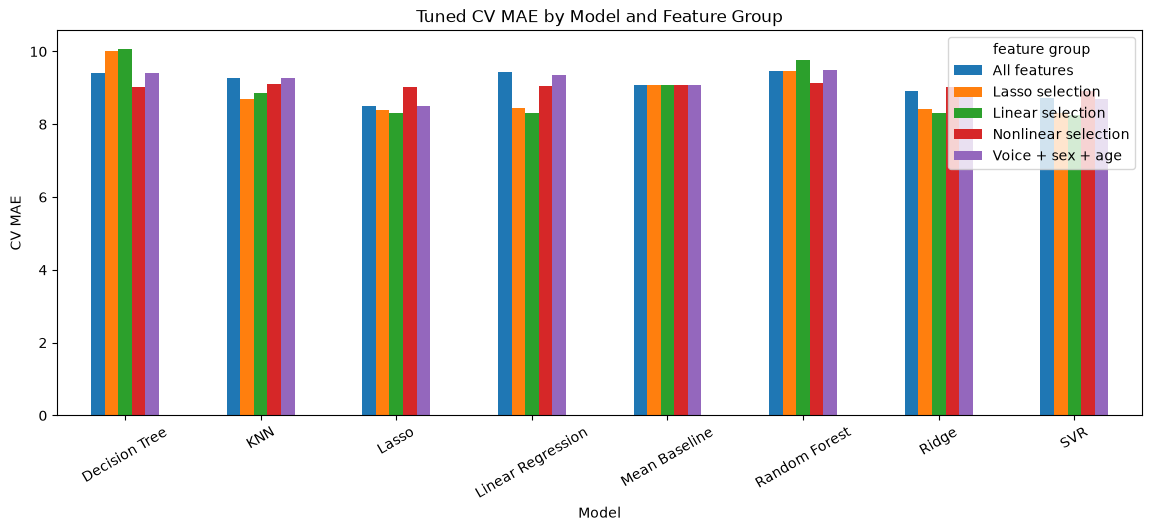

In [22]:
cv_chart = comparison.pivot(index="model", columns="feature group", values="CV MAE")
cv_chart.plot(kind="bar", figsize=(14, 5))
plt.xlabel("Model")
plt.ylabel("CV MAE")
plt.title("Tuned CV MAE by Model and Feature Group")
plt.xticks(rotation=30)
plt.show()

### Train vs CV MAE

A big gap between the two bars means the model is overfitting.

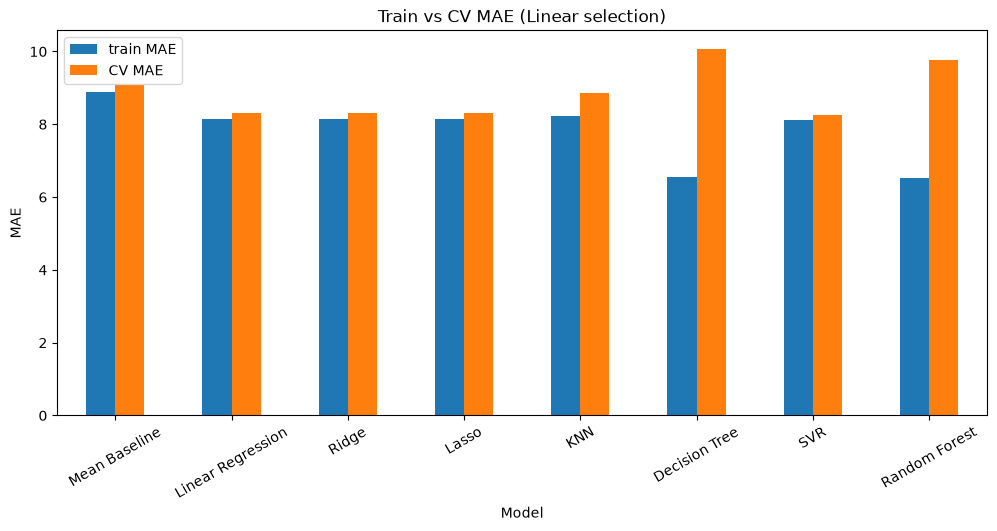

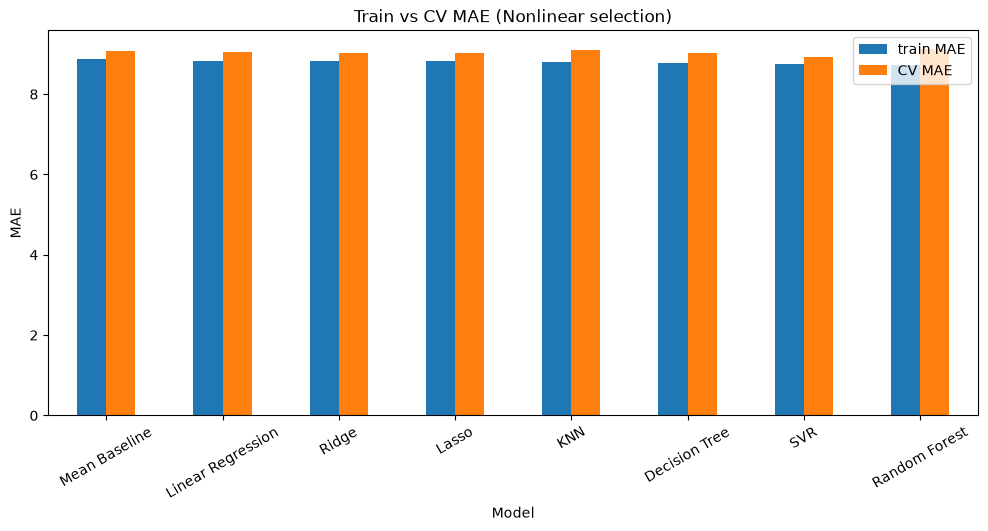

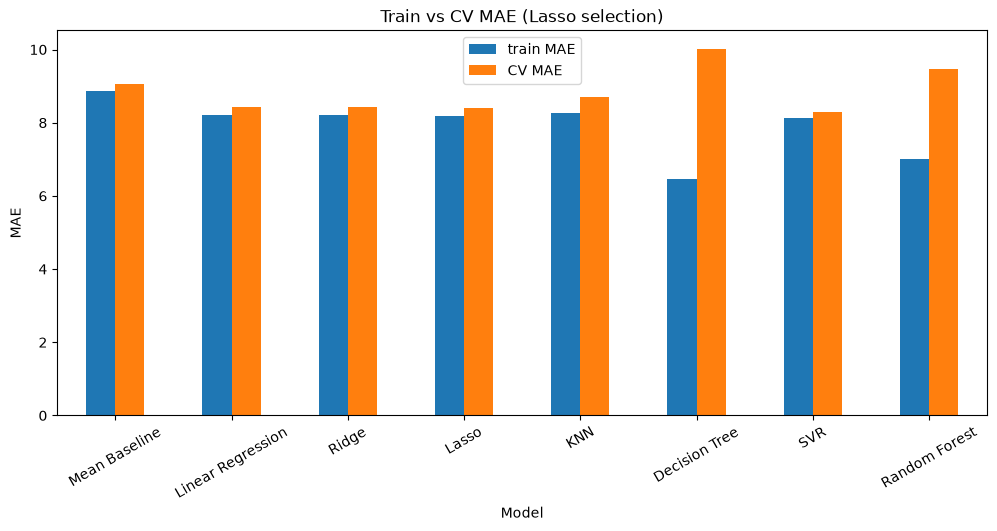

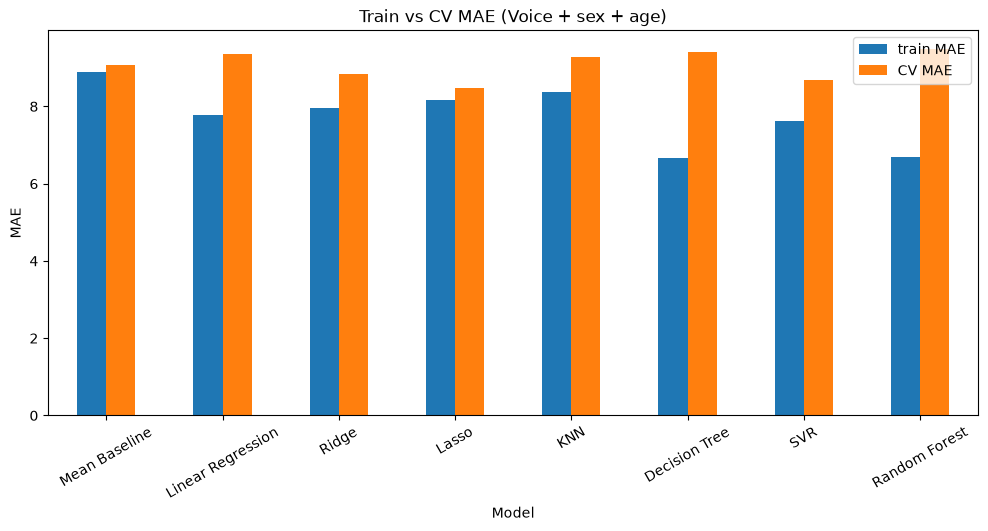

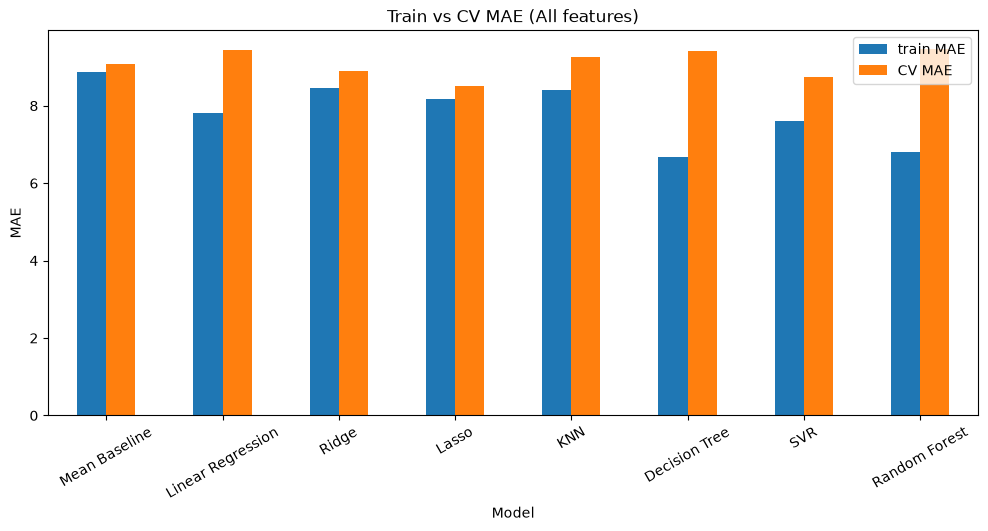

In [23]:
for group in feature_groups:
    group_table = comparison[comparison["feature group"] == group].set_index("model")
    group_table[["train MAE", "CV MAE"]].plot(kind="bar", figsize=(12, 5))
    plt.xlabel("Model")
    plt.ylabel("MAE")
    plt.title(f"Train vs CV MAE ({group})")
    plt.xticks(rotation=30)
    plt.show()

## Final Test Evaluation (TODO)

**Placeholder.** Pick the final model and feature group from the comparison above, then evaluate it once on `X_test` and `y_test`.

In [24]:
# TODO: final test evaluation goes here